<a href="https://colab.research.google.com/github/ignatmatei/AI-labs/blob/main/lab2_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Computing Lab 2: Quantum Circuit Simulator

## Introduction
Welcome to the lab 2 on Quantum Single and Multi Qubit Gates. Please follow the instructions and complete the exercises provided.

Install the packages once with `%pip install -r requirements.txt`, then restart the kernel. Keep `requirements.txt` in the same folder as this notebook. Python 3.11 or newer is required.

See [lab2_2026_cheatsheet.html](lab2_2026_cheatsheet.html) for useful functions and syntax.

In [42]:
import numpy as np
from functools import reduce


## Part 1 - Prerequisites

### 1: Python/Numpy Recap

In [3]:
# TODO: Create a variable named 'complex_var' with the complex value 3 + 4j
complex_var = 3 + 4j

# TODO: Create a numpy array named 'array_var' with values 1, 2, 3, 4
array_var = [1 , 2, 3, 4]

# TODO: Create a 2x2 numpy matrix named 'real_matrix' with real values:
# [[1, 2],
#  [3, 4]]
real_matrix = [[1, 2], [3, 4]]

# TODO: Create a 2x2 numpy matrix named 'complex_matrix' with complex values:
# [[1 + 1j, 2 + 2j],
#  [3 + 3j, 4 + 4j]]
complex_matrix = [[1 + 1j, 2 + 2j], [3 + 3j, 4 + 4j]]

# TODO: Add 'real_matrix' and 'complex_matrix' and store the result in 'result_matrix'
result_matrix = np.add(real_matrix, complex_matrix)

# TODO: Create a variable named 'angle' with the value of pi/2. Use numpy to get the value of pi.
angle = np.pi / 2

# TODO: Check whether 'angle' is approximately equal to 1.5708 (hint: use numpy's 'isclose' function)
# Store the result in 'is_approx_equal'
is_approx_equal = np.isclose(angle, 1.5708)

In [4]:
assert complex_var == 3 + 4j
assert np.array_equal(array_var, np.array([1, 2, 3, 4]))
assert np.array_equal(real_matrix, np.array([[1, 2], [3, 4]]))
assert np.array_equal(complex_matrix, np.array([[1 + 1j, 2 + 2j], [3 + 3j, 4 + 4j]]))
assert np.array_equal(result_matrix, np.array([[2 + 1j, 4 + 2j], [6 + 3j, 8 + 4j]]))
assert np.isclose(angle, np.pi / 2)
assert is_approx_equal


### 2: Check Quantum State Validity

Write a function that checks whether a given quantum state is valid (returns boolean).

In [9]:
def is_valid_state(state):
  return np.isclose(np.sum(np.abs(state)**2), 1)

In [10]:
state1 = np.array([0.6, 0.8])
state2 = np.array([0.5, 0.5])
state3 = np.array([0.70710678, 0.70710678])
state4 = np.array([0.5+0.5j, 0.5-0.5j])
state5 = np.array([1, 0])
assert is_valid_state(state1)
assert not is_valid_state(state2)
assert is_valid_state(state3)
assert is_valid_state(state4)
assert is_valid_state(state5)

### 3. X (Pauli-X or NOT gate)

Write a function that returns an X gate.

In [11]:
def X_gate():
  return np.array([[0, 1], [1, 0]])

### 4. Y (Pauli-Y gate)

Write a function that returns an Y gate.

In [12]:
def Y_gate():
  return np.array([[0, -1j], [1j, 0]])

### 5. Z (Pauli-Z gate)

Write a function that returns an Z gate.

In [13]:
def Z_gate():
  return np.array([[1, 0], [0, -1]])

### 6. H (Hadamard gate)

Write a function that returns an H gate.

In [14]:
def H_gate():
  return np.array([[1/np.sqrt(2), 1/np.sqrt(2)], [1/np.sqrt(2), -1/np.sqrt(2)]])


### 7. S (Phase gate)

Write a function that returns an S gate.

In [15]:
def S_gate():
  return np.array([[1, 0], [0, 1j]])

### 8. T (π/4 Phase gate)

Write a function that returns a T gate.

In [16]:
def T_gate():
  return np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]])

In [17]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
assert np.allclose(X_gate(), gate1)
assert np.allclose(Y_gate(), gate3)
assert np.allclose(Z_gate(), gate4)
assert np.allclose(H_gate(), gate5)
assert np.allclose(S_gate(), np.array([[1, 0], [0, 1j]]))
assert np.allclose(T_gate(), np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]]))

### 9. Compute Determinant

Write a function that computes the determinant of a given gate.

In [18]:
def compute_determinant(gate):
    return np.linalg.det(gate)


In [19]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
matrix6 = np.array([[5, 4], [3, 7]])
assert np.allclose(compute_determinant(gate1), -1)
assert np.allclose(compute_determinant(gate2), 0)
assert np.allclose(compute_determinant(gate3), -1)
assert np.allclose(compute_determinant(gate4), -1)
assert np.allclose(compute_determinant(gate5), -1)
assert np.allclose(compute_determinant(matrix6), 23)

### 10. Given a quantum gate, compute its transpose

Write a function that computes the transpose of a matrix.

In [20]:
def compute_transpose(matrix):
    return np.transpose(matrix)


In [21]:
matrix1 = np.array([[1, 2], [3, 4]])
assert np.array_equal(compute_transpose(matrix1), np.array([[1, 3], [2, 4]]))
matrix2 = np.array([[1+1j, 2-1j], [3-1j, 4+1j]])
assert np.array_equal(compute_transpose(matrix2), np.array([[1+1j, 3-1j], [2-1j, 4+1j]]))
matrix3 = np.array([[1], [2], [3]])
assert np.array_equal(compute_transpose(matrix3), np.array([[1, 2, 3]]))
matrix4 = np.array([[1+1j], [2-2j], [3]])
assert np.array_equal(compute_transpose(matrix4), np.array([[1+1j, 2-2j, 3]]))
matrix5 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
assert np.array_equal(compute_transpose(matrix5), np.array([[1, 4, 7], [2, 5, 8], [3, 6, 9]]))
matrix6 = np.array([[1+1j, 2-2j, 3+3j], [4-1j, 5+2j, 6-3j]])
assert np.array_equal(compute_transpose(matrix6), np.array([[1+1j, 4-1j], [2-2j, 5+2j], [3+3j, 6-3j]]))
matrix7 = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
assert np.array_equal(compute_transpose(matrix7), np.array([[1, 5], [2, 6], [3, 7], [4, 8]]))


### 11. Given a quantum gate, compute its adjoint

Write a function that computes the adjoint of a matrix.

In [24]:
def compute_adjoint(matrix):
    return np.conjugate(np.transpose(matrix))


In [25]:
matrix1 = np.array([[1, 2], [3, 4]])
assert np.array_equal(compute_adjoint(matrix1), np.array([[1, 3], [2, 4]]))
matrix2 = np.array([[1+1j, 2-1j], [3-1j, 4+1j]])
assert np.array_equal(compute_adjoint(matrix2), np.array([[1-1j, 3+1j], [2+1j, 4-1j]]))
matrix3 = np.array([[1], [2], [3]])
assert np.array_equal(compute_adjoint(matrix3), np.array([[1, 2, 3]]))
matrix4 = np.array([[1+1j], [2-2j], [3]])
assert np.array_equal(compute_adjoint(matrix4), np.array([[1-1j, 2+2j, 3]]))
matrix5 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
assert np.array_equal(compute_adjoint(matrix5), np.array([[1, 4, 7], [2, 5, 8], [3, 6, 9]]))
matrix6 = np.array([[1+1j, 2-2j, 3+3j], [4-1j, 5+2j, 6-3j]])
assert np.array_equal(compute_adjoint(matrix6), np.array([[1-1j, 4+1j], [2+2j, 5-2j], [3-3j, 6+3j]]))
matrix7 = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
assert np.array_equal(compute_adjoint(matrix7), np.array([[1, 5], [2, 6], [3, 7], [4, 8]]))

### 12. Given a list of quantum gates, compute their sum

Write a function that receives a np array of matrices and computes their sum.

In [29]:
def add_gates(gate_list):
    return np.sum(gate_list, axis=0)


In [30]:
gate1 = np.array([[1, 2], [3, 4]])
gate2 = np.array([[4, 3], [2, 1]])
gate3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
gate4 = np.array([[0, 1j], [-1j, 0]])
gate5 = np.array([[1, 0], [0, 1]])

assert np.array_equal(add_gates([gate1, gate2]), np.array([[5, 5], [5, 5]]))
assert np.array_equal(add_gates([gate1, gate3]), np.array([[2+1j, 4-1j], [5+1j, 5-1j]]))
assert np.array_equal(add_gates([gate3, gate4]), np.array([[1+1j, 2], [2, 1-1j]]))
assert np.array_equal(add_gates([gate1, gate4, gate5]), np.array([[2, 2+1j], [3-1j, 5]]))
assert np.array_equal(add_gates([gate2, gate5]), np.array([[5, 3], [2, 2]]))


### 13. Given a list of quantum gates, compute their product

Write a function that receives a np array of matrices and computes their product.

In [43]:
def multiply_gates(gates):
    return reduce(np.matmul, gates)

In [44]:
gate1 = np.array([[1, 2], [3, 4]])
gate2 = np.array([[4, 3], [2, 1]])
gate3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
gate4 = np.array([[0, 1j], [-1j, 0]])
gate5 = np.array([[1, 0], [0, 1]])
assert np.array_equal(multiply_gates([gate1, gate2]), np.array([[8, 5], [20, 13]]))
assert np.array_equal(multiply_gates([gate1, gate3]), np.array([[5+3j, 4-3j], [11+7j, 10-7j]]))
assert np.array_equal(multiply_gates([gate3, gate4]), np.array([[-1-2j, -1+1j], [-1-1j, -1+2j]]))
assert np.array_equal(multiply_gates([gate1, gate4, gate5]), np.array([[-2j, 1j], [-4j, 3j]]))
assert np.array_equal(multiply_gates([gate2, gate5, gate3]), np.array([[10+7j, 11-7j], [4+3j, 5-3j]]))


### 14. Given a matrix and a constant, multiply them

Write a function that receives a matrix and a constant and computes their product.

In [66]:
def multiply_constant(matrix, constant):
  return matrix * constant

In [67]:
matrix1 = np.array([[1, 2], [3, 4]])
matrix2 = np.array([[4, 3], [2, 1]])
matrix3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
matrix4 = np.array([[0, 1j], [-1j, 0]])

const1 = 2
const2 = -1
const3 = 1j
assert np.array_equal(multiply_constant(matrix1, const1), np.array([[2, 4], [6, 8]]))
assert np.array_equal(multiply_constant(matrix2, const2), np.array([[-4, -3], [-2, -1]]))
assert np.array_equal(multiply_constant(matrix3, const3), np.array([[-1+1j, 1+2j], [-1+2j, 1+1j]]))
assert np.array_equal(multiply_constant(matrix4, const1), np.array([[0, 2j], [-2j, 0]]))
assert np.array_equal(multiply_constant(matrix1, const3), np.array([[1j, 2j], [3j, 4j]]))


### 15. Given a matrix, compute its rank.

Write a function that computes the rank of a matrix.

In [45]:
def compute_rank(matrix):
    return np.linalg.matrix_rank(matrix)


In [46]:
matrix1 = np.array([[1, 2, 3], [0, 1, 4], [0, 0, 0]])
matrix2 = np.array([[2, 3], [4, 6]])
matrix3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
matrix4 = np.array([[0, 1j], [-1j, 0]])
matrix5 = np.array([[1, 2], [3, 6]])

assert compute_rank(matrix1) == 2
assert compute_rank(matrix2) == 1
assert compute_rank(matrix3) == 2
assert compute_rank(matrix4) == 2
assert compute_rank(matrix5) == 1


### 16. Check Quantum Gate Validity

Write a function that checks whether a gate is valid (returns boolean).

In [64]:
def is_valid_gate(gate):
    return np.allclose(np.matmul(gate, compute_adjoint(gate)), np.identity(gate.shape[0]))

In [65]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
matrix6 = np.array([[5, 4], [3, 7]])
assert is_valid_gate(gate1)
assert not is_valid_gate(gate2)
assert is_valid_gate(gate3)
assert is_valid_gate(gate4)
assert is_valid_gate(gate5)
assert not is_valid_gate(matrix6)

### 17. Compute Eigenvalues and Eigenvectors

Write a function that computes the eigenvalues and eigenvectors of a given matrix.

In [51]:
def get_eigen(gate):
    eigenvalues, eigenvectors = np.linalg.eig(gate)
    return eigenvalues, eigenvectors


In [52]:
gate1 = np.array([[2, 0], [0, 3]])
gate2 = np.array([[1, -1], [1, 1]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[2, 1], [1, 2]])
gate5 = np.array([[3, 2], [0, 1]])

eigenvalues1, eigenvectors1 = get_eigen(gate1)
eigenvalues2, eigenvectors2 = get_eigen(gate2)
eigenvalues3, eigenvectors3 = get_eigen(gate3)
eigenvalues4, eigenvectors4 = get_eigen(gate4)
eigenvalues5, eigenvectors5 = get_eigen(gate5)

assert np.allclose(eigenvalues1, [2, 3]) or np.allclose(eigenvalues1[::-1], [2, 3])
assert np.allclose(eigenvalues2, [1+1j, 1-1j]) or np.allclose(eigenvalues2[::-1], [1+1j, 1-1j])
assert np.allclose(eigenvalues3, [1, -1]) or np.allclose(eigenvalues3[::-1], [1, -1])
assert np.allclose(eigenvalues4, [3, 1]) or np.allclose(eigenvalues4[::-1], [3, 1])
assert np.allclose(eigenvalues5, [3, 1]) or np.allclose(eigenvalues5[::-1], [3, 1])

assert np.allclose(np.dot(gate1, eigenvectors1[:, 0]), eigenvalues1[0] * eigenvectors1[:, 0])
assert np.allclose(np.dot(gate2, eigenvectors2[:, 1]), eigenvalues2[1] * eigenvectors2[:, 1])
assert np.allclose(np.dot(gate3, eigenvectors3[:, 0]), eigenvalues3[0] * eigenvectors3[:, 0])
assert np.allclose(np.dot(gate4, eigenvectors4[:, 1]), eigenvalues4[1] * eigenvectors4[:, 1])
assert np.allclose(np.dot(gate5, eigenvectors5[:, 0]), eigenvalues5[0] * eigenvectors5[:, 0])


### 18. Convert from Computational to +/- Basis

Write a function that receives a state in computational basis and returns the state converted to +/- basis.

In [53]:
def computational_to_plus_minus(state):
    return H_gate() @ state


In [54]:
state_in_computational = np.array([0.70710678, 0.70710678])
state_in_plus_minus = np.array([1, 0])
assert np.allclose(computational_to_plus_minus(state_in_computational), state_in_plus_minus)

### 19. Convert from +/- to Computational Basis

Write a function that receives a state in +/- basis and returns the state converted to computational basis.

In [55]:
def plus_minus_to_computational(state):
    return H_gate() @ state


In [56]:
state_in_computational = np.array([0.70710678, 0.70710678])
state_in_plus_minus = np.array([1, 0])
assert np.allclose(plus_minus_to_computational(state_in_plus_minus), state_in_computational)

### 20. Apply SQG to State

Write a function that receives a state and a gate and returns the resulting state obtained by applying the gate.

In [57]:
def apply_gate(state, gate):
    return gate @ state


In [58]:
state1 = np.array([0.6, 0.8])
gate1 = np.array([[0, 1], [1, 0]])
gate3 = np.array([[0, -1j], [1j, 0]])
assert np.allclose(apply_gate(state1, gate1), np.array([0.8, 0.6]))
assert np.allclose(apply_gate(state1, gate3), np.array([-0.8j, 0.6j]))

### 21. Measure in Computational Basis

Write a function that receives a state and measures it in computational basis. The function should return 0 or 1.

Collapse the input NumPy array in place to the measured state.

In [72]:
import random

def measure_computational(state):
  amplitude1 = state[0]
  if random.random() < np.abs(amplitude1)**2:
        return 0
  else:
        return 1


In [73]:
state1 = np.array([0.6, 0.8])
state10 = np.array([1, 0])
state01 = np.array([0, 1])
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state10) == 0
assert measure_computational(state01) == 1

### 22. Measure in +/- Basis

Write a function that receives a state (in computational basis) and measures it in +/- basis. The function should return '+' or '-'

Collapse the input NumPy array in place to the measured state, keeping its coordinates in computational basis. Use an array with floating-point or complex dtype.

In [79]:
def measure_plus_minus(state):
    state_pm = computational_to_plus_minus(state)
    prob_plus = np.abs(state_pm[0])**2
    if random.random() < prob_plus:
        state[0] = 1/np.sqrt(2)
        state[1] = 1/np.sqrt(2)
        return '+'
    else:
        state[0] = 1/np.sqrt(2)
        state[1] = -1/np.sqrt(2)
        return '-'

In [80]:
statepm10 = np.array([1/np.sqrt(2), 1/np.sqrt(2)])
statepm01 = np.array([1/np.sqrt(2), -1/np.sqrt(2)])
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm01) == '-'

### Conclusion
Congrats on mastering single qubit gates! As we embark on quantum entanglement, just remember: the math might feel like trying to untangle earbuds from your pocket. Stay patient and untangled! 🎧

## Part 2 - Multi-Qubit Simulator

In [81]:
import numpy as np

In [99]:
class State:
    def __init__(self, n_qubits):
        self.n_qubits = n_qubits
        # Initialize state to |00...0>
        self.state = np.zeros(2**n_qubits, dtype=complex)
        self.state[0] = 1.0

    def initialize_state(self, qubit_values):
        self.n_qubits = len(qubit_values)
        self.state = np.zeros(2**self.n_qubits, dtype=complex)
        # Map classical bit values like [0, 1, 1, 0, 0] to the corresponding basis index
        idx = 0
        for bit in qubit_values:
            idx = (idx << 1) | bit
        self.state[idx] = 1.0

    def apply_gate(self, gate, n_gate, starting_qubit):
        # Construct full multi-qubit operator via Kronecker products
        # Qubit 0 is the leftmost (most significant bit in integer representation)
        op = np.array([[1.0]])
        i = 0
        while i < self.n_qubits:
            if i == starting_qubit:
                op = np.kron(op, gate)
                i += n_gate
            else:
                op = np.kron(op, np.eye(2))
                i += 1
        self.state = op @ self.state

    def apply_H_gate(self, target_qubit):
        self.apply_gate(H_gate(), 1, target_qubit)

    def apply_X_gate(self, target_qubit):
        self.apply_gate(X_gate(), 1, target_qubit)

    def apply_S_gate(self, target_qubit):
        self.apply_gate(S_gate(), 1, target_qubit)

    def apply_CNOT_gate(self, control_qubit):
        # CNOT gate with standard ordering where control_qubit is control and target is control + 1
        cnot_matrix = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
            [0, 0, 0, 1],
            [0, 0, 1, 0]
        ])
        self.apply_gate(cnot_matrix, 2, control_qubit)

    def apply_CH_gate(self, control_qubit):
        # Controlled-H gate
        ch_matrix = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
            [0, 0, 1/np.sqrt(2), 1/np.sqrt(2)],
            [0, 0, 1/np.sqrt(2), -1/np.sqrt(2)]
        ])
        self.apply_gate(ch_matrix, 2, control_qubit)

    def apply_SWAP_gate(self, starting_qubit):
        # SWAP gate
        swap_matrix = np.array([
            [1, 0, 0, 0],
            [0, 0, 1, 0],
            [0, 1, 0, 0],
            [0, 0, 0, 1]
        ])
        self.apply_gate(swap_matrix, 2, starting_qubit)

    def apply_CNOT10_gate(self, target_qubit):
        # Reversed CNOT: first bit is target and second is control
        cnot10_matrix = np.array([
            [1, 0, 0, 0],
            [0, 0, 0, 1],
            [0, 0, 1, 0],
            [0, 1, 0, 0]
        ])
        self.apply_gate(cnot10_matrix, 2, target_qubit)

    def apply_TOFFOLI_gate(self, control1_qubit):
        # Toffoli gate acting on qubits starting at control1_qubit
        toffoli_matrix = np.eye(8)
        toffoli_matrix[6, 6] = 0
        toffoli_matrix[6, 7] = 1
        toffoli_matrix[7, 6] = 1
        toffoli_matrix[7, 7] = 0
        self.apply_gate(toffoli_matrix, 3, control1_qubit)

    def sample(self):
        probabilities = np.abs(self.state) ** 2
        outcome_idx = np.random.choice(len(self.state), p=probabilities)
        # Convert outcome index to list of bit values
        bits = [int(x) for x in format(outcome_idx, f'0{self.n_qubits}b')]
        return np.array(bits)

    def produce_measurement(self):
        probabilities = np.abs(self.state) ** 2
        outcome_idx = np.random.choice(len(self.state), p=probabilities)

        # Collapse the state to the measured computational basis state
        self.state = np.zeros_like(self.state)
        self.state[outcome_idx] = 1.0

        bits = [int(x) for x in format(outcome_idx, f'0{self.n_qubits}b')]
        return np.array(bits)

In [102]:
qstate = State(5)
qstate.initialize_state([0, 1, 1, 0, 0])
qstate.apply_H_gate(0)
qstate.apply_X_gate(1)
qstate.apply_CNOT10_gate(0)
print("Sample 1:", qstate.sample())
print("Sample 2:", qstate.sample())
print("Sample 3:", qstate.sample())

Sample 1: [0 0 1 0 0]
Sample 2: [1 0 1 0 0]
Sample 3: [1 0 1 0 0]


#### 2.1: Define state
Fill in the `__init__` function.

An n-qubit state is an array of 2^n coefficients (one for each possible value of the qubits).

Use complex coefficients. Qubit 0 is the leftmost bit in a basis label: `|q0 q1 ...>`. The initial state is `|00...0>`.

#### 2.2: Initialize state
Fill in the `initialize_state` function.

The function receives an array of desired value for each qubit, e.g. `[0,1,0,0]` for a 4-qubit system. The function should set the state accordingly.

#### 2.3: Apply a gate
Fill in the `apply_gate` function

This function generates the unitary matrix which applies the `gate` gate to the current `state`. The parameter `n_gate` represents the number of qubits affected by the gate (e.g. for a `H` gate it would be 1; for a `CNOT` gate it would be 2). The `starting_qubit` represents the first qubit affected by the gate.

Hint: `np.kron`


#### 2.4: Define single qubit gates
Fill in the functions to define the H, X, S gates.

Hint: use `apply_gate`

#### 2.5: Define multi qubit gates
Fill in the functions to define the CNOT, CH, SWAP, Toffoli gates. Hint: use `apply_gate`

The CNOT10 represents a reverse CNOT (i.e. first bit is the target and second is the control). Exercise: compute the 2-qubit matrix for CNOT10.


#### 2.6: Sample the state
Fill in the `sample` function.

The function should randomly sample according to state probabilities and output an array of qubit values (e.g. `[0,0,1,0]` for a 4-qubit system). DO NOT collapse the state.

#### 2.7: Measure the state
Fill in the `produce_measurement` function.

The function should randomly measure according to state probabilities and output an array of qubit values (e.g. `[0,0,1,0]` for a 4-qubit system). Collapse the state to the measured computational basis state. An immediate second measurement should return the same result.


In [103]:
print(qstate.produce_measurement())
print(qstate.produce_measurement())

[0 0 1 0 0]
[0 0 1 0 0]


## Part 3 - Implement Circuit

### 3.1: Implement circuit in your simulator

Implement the following circuit using your code.

Output the following:
 - the magnitude and probability for each output
 - the outputs of 10 random samples (without collapsing the stored state)


![image.png](attachment:08acecb7-f3af-4e76-bcb1-bc867aadd46b.png)

In [ ]:
circuit = State(4)
# TODO task 3.1

### 3.2: Implement circuit in Quirk

Implement the same circuit in https://algassert.com/quirk and compare the results with your code.

Quirk treats the top wire as the least significant bit. Reverse its basis bitstrings when comparing with the `q0 q1 q2 q3` order used by our simulator.

### 3.3: Implement circuit in IBM Qiskit

#### Qiskit local

Implement the same circuit using Qiskit, run it using the local Qiskit Aer simulator and compare the results with your code.

Use the packages from `requirements.txt`.

Hint: read the [QuantumCircuit documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit).


In [82]:
# EXAMPLE QISKIT USAGE
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

# Example circuit: 2-qubit Bell state
bell_qc = QuantumCircuit(2)
bell_qc.h(0)
bell_qc.cx(0, 1)

# Keep the original circuit without measurements for statevector calculations.
print("Statevector:", Statevector.from_instruction(bell_qc).data)
bell_measured = bell_qc.copy()
bell_measured.measure_all()

# Simulate the circuit
simulator = AerSimulator()
bell_compiled = transpile(bell_measured, simulator)
bell_result = simulator.run(bell_compiled, shots=1024, seed_simulator=2026).result()

# Get the results and plot
bell_counts = bell_result.get_counts()
plot_histogram(bell_counts)


ModuleNotFoundError: No module named 'qiskit'

Implement the four-qubit circuit from Part 3.1 below. Use the same wire numbers: the top wire is qubit 0. Do not add measurement gates yet.

Qiskit writes bitstrings in the order `q3 q2 q1 q0`, while our simulator uses `q0 q1 q2 q3`. The comparison cell reverses Qiskit's output ordering. This changes the displayed ordering, not the circuit.


In [ ]:
qc = QuantumCircuit(4)
# TODO task 3.3: implement the same four-qubit circuit.


In [ ]:
# Exact amplitudes, in the same qubit order as our simulator.
qiskit_state = Statevector.from_instruction(qc).reverse_qargs().data
print("Amplitudes:", qiskit_state)
print("Probabilities:", np.abs(qiskit_state) ** 2)

# Sample repeated measurements of fresh copies of the circuit.
qc_measured = qc.copy()
qc_measured.measure_all()
qc_compiled = transpile(qc_measured, simulator)
result = simulator.run(qc_compiled, shots=1024, seed_simulator=2026).result()
counts = result.get_counts()
counts_lab_order = {bits[::-1]: count for bits, count in counts.items()}
plot_histogram(counts_lab_order)


### 3.4: Run Qiskit on real quantum hardware

Run the same four-qubit circuit on a real IBM quantum device and compare the results with the ideal simulation.

Create an API key and select an instance at [IBM Quantum Platform](https://quantum.cloud.ibm.com/). Set the environment variables `IBM_QUANTUM_API_KEY` and `IBM_QUANTUM_INSTANCE_CRN` using that key and the instance CRN.

Set `RUN_ON_HARDWARE = True` only when you are ready to submit a real job to the selected instance. With the default `False`, this cell skips hardware execution. Keep your API key out of the submitted notebook.

[Account setup](https://quantum.cloud.ibm.com/docs/en/guides/initialize-account) · [Sampler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/executor-sampler-sampler)


In [ ]:
# EXAMPLE IBM QUANTUM USAGE
RUN_ON_HARDWARE = False

if RUN_ON_HARDWARE:
    import os
    from qiskit_ibm_runtime import QiskitRuntimeService
    from qiskit_ibm_runtime.executor_sampler import Sampler
    from qiskit.transpiler import generate_preset_pass_manager
    from IPython.display import display

    api_key = os.environ.get("IBM_QUANTUM_API_KEY")
    instance_crn = os.environ.get("IBM_QUANTUM_INSTANCE_CRN")
    if not api_key or not instance_crn:
        raise ValueError("Set IBM_QUANTUM_API_KEY and IBM_QUANTUM_INSTANCE_CRN first.")

    service = QiskitRuntimeService(
        channel="ibm_quantum_platform", token=api_key, instance=instance_crn
    )
    backend = service.least_busy(
        operational=True, simulator=False, min_num_qubits=qc.num_qubits
    )
    print("Backend:", backend.name)

    # Compile the same measured circuit for the selected device.
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_qc = pass_manager.run(qc_measured)

    sampler = Sampler(mode=backend)
    job = sampler.run([isa_qc], shots=1024)
    print("Job ID:", job.job_id())
    hardware_counts = job.result()[0].data.meas.get_counts()
    hardware_counts_lab_order = {
        bits[::-1]: count for bits, count in hardware_counts.items()
    }
    display(plot_histogram(hardware_counts_lab_order))
else:
    print("Hardware execution skipped. Set RUN_ON_HARDWARE = True when ready.")


## Part 4 - Representation

### 23. Change to Polar Coordinates

Write a function that receives a state and computes its polar coordinates. The returned outputs must be theta (the angle), phi (the phase), and omega (the global phase which can be ignored).
Hint: https://quantumcomputing.stackexchange.com/questions/26431/can-i-convert-a-qubit-in-complex-form-to-polar-form

Use `0 <= theta <= pi` and phases in `[-pi, pi]`. At either pole, use `phi = 0` and take `omega` from the nonzero coefficient.

In [108]:
def to_polar(state):
    state = np.array(state, dtype=complex)
    state = state / np.linalg.norm(state)

    if not np.isclose(np.abs(state[0]), 0):
        omega = np.angle(state[0])
    else:
        omega = np.angle(state[1])

    state_dephased = state * np.exp(-1j * omega)

    theta = 2 * np.arccos(np.clip(np.abs(state_dephased[0]), 0.0, 1.0))

    if np.isclose(theta, 0) or np.isclose(theta, np.pi):
        phi = 0.0
    else:
        phi = np.angle(state_dephased[1])

    return theta, phi, omega

In [113]:
# 1. Basic |0> state
state_1 = [1, 0]
expected_1 = (0, 0, 0)
result_1 = to_polar(state_1)
assert np.isclose(result_1, expected_1).all(), f"Expected {expected_1}, got {result_1}"

# 2. Basic |1> state
state_2 = [0, 1]
expected_2 = (np.pi, 0, 0)
result_2 = to_polar(state_2)
assert np.isclose(result_2, expected_2).all(), f"Expected {expected_2}, got {result_2}"

# 3. Equal superposition with no phase difference
state_3 = [np.sqrt(0.5), np.sqrt(0.5)]
expected_3 = (np.pi/2, 0, 0)
result_3 = to_polar(state_3)
assert np.isclose(result_3, expected_3).all(), f"Expected {expected_3}, got {result_3}"

# 4. Equal superposition with a phase difference
state_4 = [np.sqrt(0.5), np.sqrt(0.5) * np.exp(1j * np.pi/3)]
expected_4 = (np.pi/2, np.pi/3, 0)
result_4 = to_polar(state_4)
assert np.isclose(result_4, expected_4).all(), f"Expected {expected_4}, got {result_4}"

# 5. Complex coefficients
state_5 = [1/3 + 2j/3, 2/3 - 1j/3]
state_5 = np.array(state_5) / np.linalg.norm(state_5)
expected_5 = (np.pi/2, -np.pi/2, 1.1071487177940904)
result_5 = to_polar(state_5)
assert np.isclose(result_5, expected_5).all(), f"Expected {expected_5}, got {result_5}"

# 6. Another complex coefficient example
state_6 = [0.5 + 0.5j, 0.5 - 0.5j]
expected_6 = (np.pi/2, -np.pi/2, np.pi/4)
result_6 = to_polar(state_6)
assert np.isclose(result_6, expected_6).all(), f"Expected {expected_6}, got {result_6}"

# 7. Yet another complex coefficient case
state_7 = [0.6 + 0.8j, -0.8 + 0.6j]
state_7 = np.array(state_7) / np.linalg.norm(state_7)
expected_7 = (np.pi/2, np.pi/2, 0.9272952180016122)
result_7 = to_polar(state_7)
assert np.isclose(result_7, expected_7).all(), f"Expected {expected_7}, got {result_7}"
print("All to_polar tests passed successfully!")

All to_polar tests passed successfully!


### 24. Represent the probabilities of measurement

Write a function that receives a state (in computational basis) and draws a bar chart to represent the probabilities of measurement in computational basis.

In [107]:
import matplotlib.pyplot as plt
import numpy as np

def plot_state_probabilities(state):
    probabilities = np.abs(state)**2
    labels = [format(i, f'0{int(np.log2(len(state)))}b') for i in range(len(state))]

    plt.figure(figsize=(6, 4))
    plt.bar(labels, probabilities, color='skyblue', edgecolor='black')
    plt.xlabel('Computational Basis States')
    plt.ylabel('Probability')
    plt.title('Measurement Probabilities')
    plt.ylim(0, 1.1)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

Plotting probabilities for state: |0>


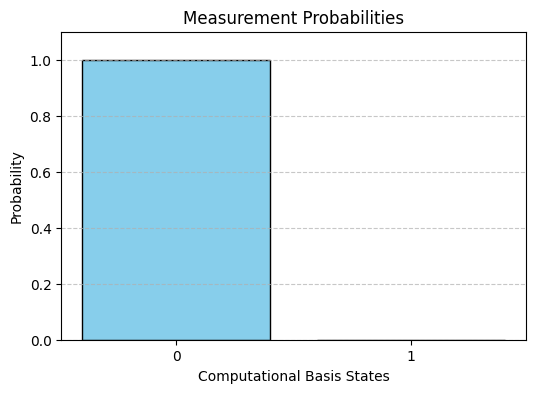

Plotting probabilities for a 3-qubit state in equal superposition (Greenberger-Horne-Zeilinger state / GHZ)


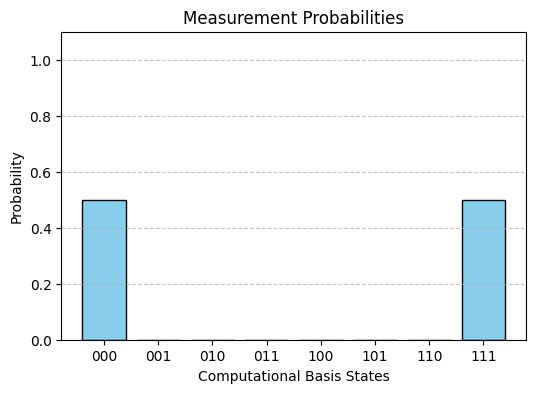

In [114]:
# Test plot_state_probabilities with single and multi-qubit states
print("Plotting probabilities for state: |0>")
plot_state_probabilities(np.array([1.0, 0.0]))

print("Plotting probabilities for a 3-qubit state in equal superposition (Greenberger-Horne-Zeilinger state / GHZ)")
ghz_state = np.zeros(8, dtype=complex)
ghz_state[0] = 1/np.sqrt(2)
ghz_state[7] = 1/np.sqrt(2)
plot_state_probabilities(ghz_state)

### 25. Represent the Bloch sphere

Write a function that receives a state (in computational basis) and represents it as a Bloch sphere.

Use a normalized single-qubit pure state.

In [116]:
import matplotlib.pyplot as plt
import numpy as np

def plot_bloch_representation(state):
    theta, phi, _ = to_polar(state)

    # Calculate Cartesian coordinates on the Bloch Sphere
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection='3d')

    # Draw Bloch sphere surface wireframe
    u = np.linspace(0, 2 * np.pi, 100)
    v = np.linspace(0, np.pi, 100)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones(np.size(u)), np.cos(v))
    ax.plot_wireframe(xs, ys, zs, color='lightgray', alpha=0.3, linewidths=0.5)

    # Draw axes
    ax.plot([-1, 1], [0, 0], [0, 0], color='black', alpha=0.5)
    ax.plot([0, 0], [-1, 1], [0, 0], color='black', alpha=0.5)
    ax.plot([0, 0], [0, 0], [-1, 1], color='black', alpha=0.5)

    # Draw state vector
    ax.quiver(0, 0, 0, x, y, z, color='red', arrow_length_ratio=0.1, linewidth=2)

    # Labels
    ax.text(1.1, 0, 0, 'x')
    ax.text(0, 1.1, 0, 'y')
    ax.text(0, 0, 1.1, '|0>')
    ax.text(0, 0, -1.2, '|1>')

    ax.set_xlim([-1, 1])
    ax.set_ylim([-1, 1])
    ax.set_zlim([-1, 1])
    ax.set_title('Bloch Sphere Representation')
    plt.show()

Plotting Bloch Sphere for |0> state:


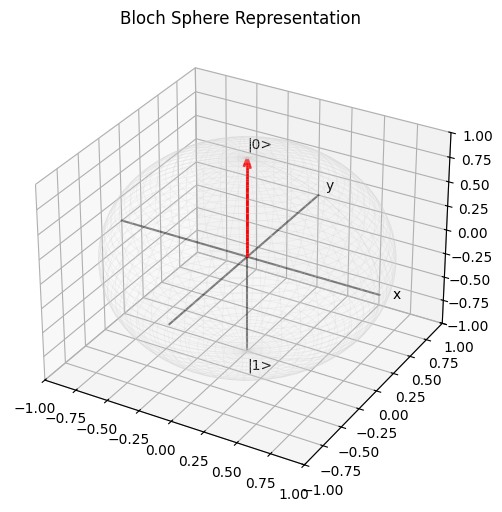

Plotting Bloch Sphere for |+> state:


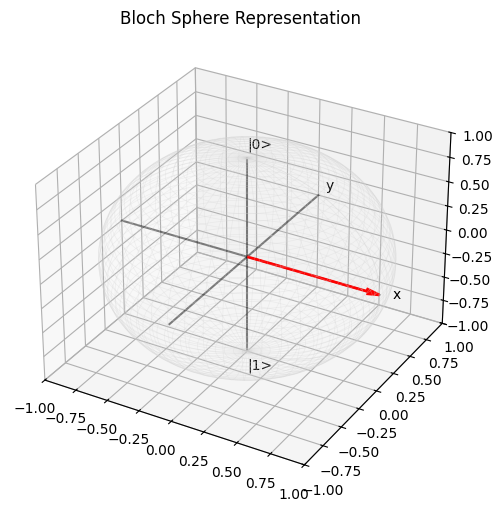

In [117]:
# Test Bloch sphere representation with |0>, |1>, and |+> states
print("Plotting Bloch Sphere for |0> state:")
plot_bloch_representation([1, 0])

print("Plotting Bloch Sphere for |+> state:")
plot_bloch_representation([1/np.sqrt(2), 1/np.sqrt(2)])

### 26. Represent eigenvalues and eigenvectors

Write a function that receives a gate and represents its eigenvectors. Suggestion: take random points on a plane (i.e. random vectors) and represent with lines or arrows the effect of the matrix on those vectors. The eigenvectors should change only by a constant factor, which is the eigenvalue.

For this 2D plot, use a gate with real entries and real eigenvectors, such as X, Z or H.

In [112]:
import matplotlib.pyplot as plt
import numpy as np

def plot_gate_representation(gate):
  eigenvalues, eigenvectors = np.linalg.eig(gate)
  plt.quiver(0, 0, eigenvectors[0, 0], eigenvectors[1, 0], angles='xy', scale_units='xy', scale=1)
  plt.quiver(0, 0, eigenvectors[0, 1], eigenvectors[1, 1], angles='xy', scale_units='xy', scale=1)
  plt.axis('equal')
  plt.show()


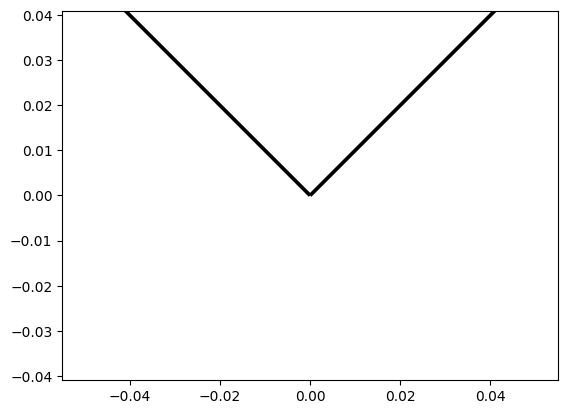

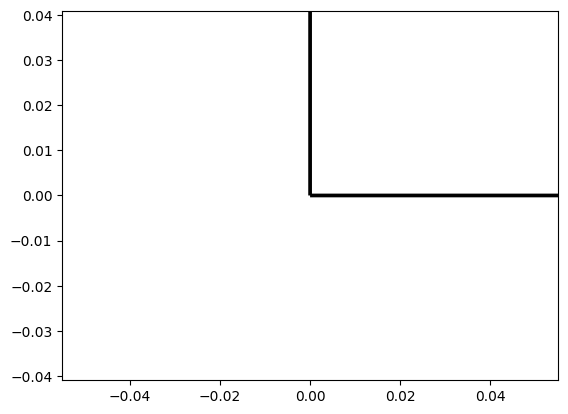

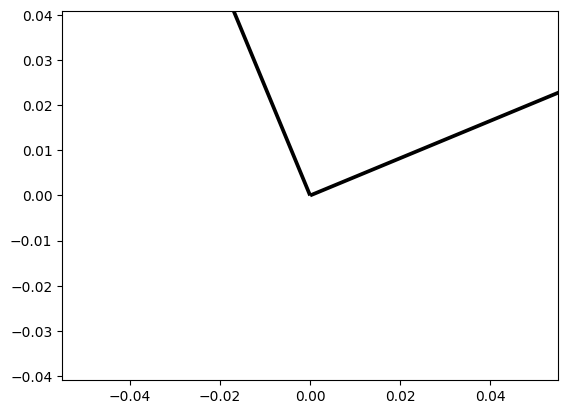

In [85]:
# TODO: test with some gates
plot_gate_representation(X_gate())
plot_gate_representation(Z_gate())
plot_gate_representation(H_gate())

### 27. Represent state amplitudes

Write a function that receives a state (in computational basis) and draws a bar chart for the real and imaginary parts of each amplitude. Label each amplitude with its computational basis state.

In [87]:
def plot_state_amplitudes(state):
  amplitude0real = state[0].real
  amplitude0im = state[0].imag
  amplitude1real = state[1].real
  amplitude1im = state[1].imag
  plt.bar(['0', '1'], [amplitude0real, amplitude1real])
  plt.bar(['0', '1'], [amplitude0im, amplitude1im])

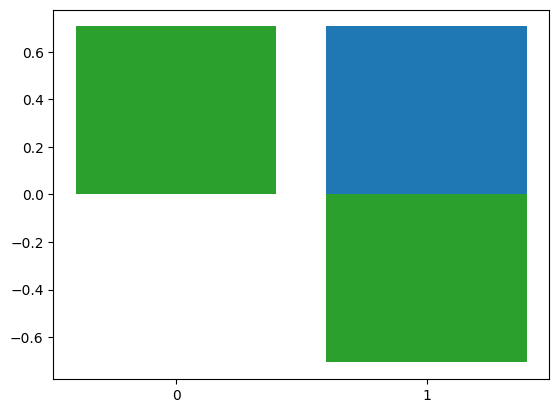

In [89]:
# TODO: test with some states
plot_state_amplitudes(np.array([1/np.sqrt(2), 1/np.sqrt(2)]))
plot_state_amplitudes(np.array([1/np.sqrt(2), -1/np.sqrt(2)]))

## Conclusion
Congrats! You have done real quantum!